# 5. Jet energetics across η

    Jet powers from the MCMC posteriors, the cold-proton systematic, and the jet power against the disc luminosity.

In [1]:
%run mg3_setup.py

JetSeT version: 1.3.0
---> excluding  data_set/s ['-1']
filter -1 46
current datasets
dataset 0.0
---> data sets left after filtering None
---> data len after filtering=46
points: 46  (detections 40, UL 6), in fit range 38, in 3-79 keV 11


===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: z_cosm to  z_cosm
===> setting C threads to 8
eta = 0.057: 200 draws done
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending o

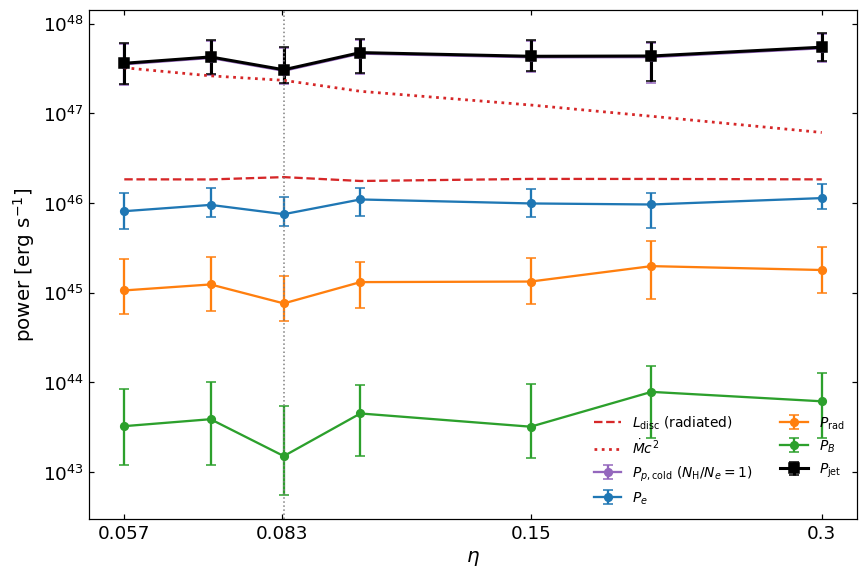

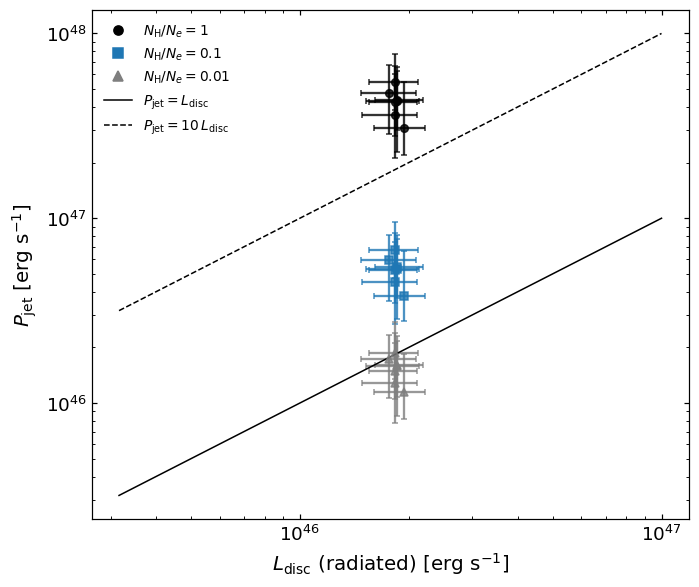

In [2]:
NH_BASE    = 1.0                   # one cold proton per relativistic electron (Celotti & Ghisellini 2008)
NH_VALUES  = [1.0, 0.1, 0.01]      # baseline + alternatives
n_draws_en = 200                   # posterior draws per eta
L_EDD_COEFF = 1.26e38              # erg/s per Msun

keys = ['jet_L_e', 'jet_L_B', 'jet_L_rad', 'jet_L_p_cold', 'jet_L_kin', 'jet_L_tot', 'U_e', 'U_B']

def q3(arr):
    """median, -1sigma, +1sigma"""
    lo, med, hi = np.percentile(arr, [16, 50, 84])
    return med, med - lo, hi - med

# 2. loop over the grid, energetics for every posterior draw
energ = {}           # energ[eta][key] = array over draws
rng = np.random.default_rng(7)

for eta in eta_grid:
    tag = eta_tag(eta)
    if not os.path.exists(f'chain_{tag}_7p.npz'):
        print(f"missing chain: {tag}_7p")
        continue

    d = np.load(f'chain_{tag}_7p.npz')
    samples, labels = d['samples'], list(d['labels'])
    idx = rng.choice(len(samples), size=n_draws_en, replace=False)

    fit_model = FitModel.load_model(f'Model_Minuit_{tag}.pkl')
    jet = fit_model.jet_leptonic
    jet.set_external_field_transf(EXT_FIELD_FRAME)
    jet.set_num_c_threads(8)
    jet.parameters.NH_cold_to_rel_e.val = NH_BASE

    out = {k: np.zeros(n_draws_en) for k in keys}
    out['L_Disk'] = np.zeros(n_draws_en)
    out['M_BH']   = np.zeros(n_draws_en)

    for k_draw, j in enumerate(idx):
        for i, pname in enumerate(labels):
            jet.parameters.get_par_by_name(pname).val = samples[j, i]
        jet.eval()
        jet.energetic_report(verbose=False)
        for k in keys:
            out[k][k_draw] = jet.energetic_dict[k]
        out['L_Disk'][k_draw] = jet.parameters.L_Disk.val
        out['M_BH'][k_draw]   = jet.parameters.M_BH.val

    # physical disc quantities
    out['L_disc_rad'] = out['L_Disk'] / (12 * eta)          # radiated disc luminosity
    out['Mdot_c2']    = out['L_disc_rad'] / eta              # FIXED: accretion power for efficiency eta
    out['L_Edd']      = L_EDD_COEFF * out['M_BH']
    energ[eta] = out
    print(f"eta = {eta:.3f}: {n_draws_en} draws done")

etas_en = list(energ.keys())

# 3. check that P_p,cold scales linearly with NH (one draw, eta = 1/12)
jet.parameters.NH_cold_to_rel_e.val = 0.1
jet.eval()
jet.energetic_report(verbose=False)
P_p_01 = jet.energetic_dict['jet_L_p_cold']
jet.parameters.NH_cold_to_rel_e.val = 1.0
jet.eval()
jet.energetic_report(verbose=False)
print(f"\nNH check: P_p(0.1)/P_p(1) = {P_p_01 / jet.energetic_dict['jet_L_p_cold']:.4f}  (expected 0.1)")

def P_jet_NH(o, NH):
    """total jet power for a given cold-proton ratio (P_p computed at NH = 1)"""
    return o['jet_L_e'] + o['jet_L_B'] + o['jet_L_rad'] + NH * o['jet_L_p_cold']

# 4. summary table across eta (NH = 1)
rows = []
for eta in etas_en:
    o = energ[eta]
    Pj = P_jet_NH(o, 1.0)
    row = {'eta': f"{eta:.3f}"}
    for lab, arr, sc in [('P_e [1e45]',        o['jet_L_e'],      1e45),
                         ('P_B [1e44]',        o['jet_L_B'],      1e44),
                         ('P_rad [1e45]',      o['jet_L_rad'],    1e45),
                         ('P_p [1e46]',        o['jet_L_p_cold'], 1e46),
                         ('P_jet [1e46]',      Pj,                1e46),
                         ('L_disc [1e46]',     o['L_disc_rad'],   1e46),
                         ('Mdot c2 [1e47]',    o['Mdot_c2'],      1e47)]:
        m, lo, hi = q3(arr / sc)
        row[lab] = f"{m:.2f} (-{lo:.2f}/+{hi:.2f})"
    for lab, arr in [('U_B/U_e',          o['U_B'] / o['U_e']),
                     ('P_jet/L_disc',     Pj / o['L_disc_rad']),
                     ('P_jet/Mdot c2',    Pj / o['Mdot_c2']),
                     ('P_rad/P_jet',      o['jet_L_rad'] / Pj),
                     ('P_jet/L_Edd',      Pj / o['L_Edd'])]:
        m, lo, hi = q3(arr)
        row[lab] = f"{m:.3g} (-{lo:.2g}/+{hi:.2g})"
    rows.append(row)

en_table = pd.DataFrame(rows)
print("\n=== Jet energetics, NH_cold/rel_e = 1 (median and 68%) ===")
print(en_table.to_string(index=False))
en_table.to_csv('jet_energetics_eta_grid_NH1.csv', index=False)

# 5. proton-content systematic (all eta, NH = 1, 0.1, 0.01)
rows = []
for eta in etas_en:
    o = energ[eta]
    row = {'eta': f"{eta:.3f}"}
    for NH in NH_VALUES:
        Pj = P_jet_NH(o, NH)
        m, lo, hi = q3(Pj / 1e46)
        row[f'P_jet(NH={NH:g}) [1e46]'] = f"{m:.2f} (-{lo:.2f}/+{hi:.2f})"
        row[f'P_jet/L_disc (NH={NH:g})'] = f"{np.median(Pj / o['L_disc_rad']):.2f}"
    rows.append(row)
nh_table = pd.DataFrame(rows)
print("\n=== Proton-content systematic ===")
print(nh_table.to_string(index=False))
nh_table.to_csv('jet_energetics_NH_systematic.csv', index=False)

# 6. save numbers for the thesis and for the BH-growth part
en_summary = {}
for eta in etas_en:
    o = energ[eta]
    en_summary[f"{eta:.3f}"] = {
        'P_e':  q3(o['jet_L_e']), 'P_B': q3(o['jet_L_B']), 'P_rad': q3(o['jet_L_rad']),
        'P_p_NH1': q3(o['jet_L_p_cold']),
        'P_jet': {f"NH={NH:g}": q3(P_jet_NH(o, NH)) for NH in NH_VALUES},
        'P_jet_over_Ldisc': {f"NH={NH:g}": q3(P_jet_NH(o, NH) / o['L_disc_rad']) for NH in NH_VALUES},
        'P_jet_over_Mdotc2': {f"NH={NH:g}": q3(P_jet_NH(o, NH) / o['Mdot_c2']) for NH in NH_VALUES},
        'U_B_over_U_e': q3(o['U_B'] / o['U_e']),
        'L_disc_rad': q3(o['L_disc_rad']), 'Mdot_c2': q3(o['Mdot_c2']),
    }
with open('jet_energetics_summary.json', 'w') as f:
    json.dump(en_summary, f, indent=2, default=float)
print("\nsaved: jet_energetics_eta_grid_NH1.csv, jet_energetics_NH_systematic.csv, jet_energetics_summary.json")

# 7. figure - power components vs eta (NH = 1), disc quantities for reference
fig, ax = plt.subplots(figsize=(9, 6))
comp_plot = [('jet_L_p_cold', r'$P_{p,\rm cold}$ ($N_{\rm H}/N_e = 1$)', 'tab:purple'),
             ('jet_L_e',      r'$P_e$',                                  'tab:blue'),
             ('jet_L_rad',    r'$P_{\rm rad}$',                          'tab:orange'),
             ('jet_L_B',      r'$P_B$',                                  'tab:green')]
for key, lab, col in comp_plot:
    m  = np.array([q3(energ[e][key])[0] for e in etas_en])
    lo = np.array([q3(energ[e][key])[1] for e in etas_en])
    hi = np.array([q3(energ[e][key])[2] for e in etas_en])
    ax.errorbar(etas_en, m, yerr=[lo, hi], fmt='o-', color=col, ms=5, capsize=3, label=lab)

m  = np.array([q3(P_jet_NH(energ[e], 1.0))[0] for e in etas_en])
lo = np.array([q3(P_jet_NH(energ[e], 1.0))[1] for e in etas_en])
hi = np.array([q3(P_jet_NH(energ[e], 1.0))[2] for e in etas_en])
ax.errorbar(etas_en, m, yerr=[lo, hi], fmt='s-', color='k', ms=6, capsize=3, lw=2, label=r'$P_{\rm jet}$')

ax.plot(etas_en, [np.median(energ[e]['L_disc_rad']) for e in etas_en], '--', color='tab:red',
        lw=1.5, label=r'$L_{\rm disc}$ (radiated)')
ax.plot(etas_en, [np.median(energ[e]['Mdot_c2']) for e in etas_en], ':', color='tab:red',
        lw=1.8, label=r'$\dot M c^2$')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xticks([0.057, 0.083, 0.15, 0.3])
ax.set_xticklabels(['0.057', '0.083', '0.15', '0.3'])
ax.minorticks_off()
ax.axvline(1/12, color='gray', ls=':', lw=1)
ax.set_xlabel(r'$\eta$')
ax.set_ylabel(r'power [erg s$^{-1}$]')
ax.legend(fontsize=9, frameon=False, ncol=2, loc='lower right')
plt.savefig(os.path.join(FIG_DIR, 'jet_energetics_vs_eta.png'), bbox_inches='tight')
plt.show()

# 8. figure - P_jet vs L_disc for the three proton contents
fig, ax = plt.subplots(figsize=(7, 6))
for NH, mk, col in zip(NH_VALUES, ['o', 's', '^'], ['k', 'tab:blue', 'tab:gray']):
    for eta in etas_en:
        o = energ[eta]
        x = q3(o['L_disc_rad']); y = q3(P_jet_NH(o, NH))
        ax.errorbar(x[0], y[0], xerr=[[x[1]], [x[2]]], yerr=[[y[1]], [y[2]]],
                    fmt=mk, color=col, ms=5, capsize=2, alpha=0.8)
    ax.plot([], [], mk, color=col, label=rf'$N_{{\rm H}}/N_e = {NH:g}$')

xx = np.logspace(45.5, 47, 10)
ax.plot(xx, xx, 'k-', lw=1, label=r'$P_{\rm jet} = L_{\rm disc}$')
ax.plot(xx, 10 * xx, 'k--', lw=1, label=r'$P_{\rm jet} = 10\,L_{\rm disc}$')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$L_{\rm disc}$ (radiated) [erg s$^{-1}$]')
ax.set_ylabel(r'$P_{\rm jet}$ [erg s$^{-1}$]')
ax.legend(fontsize=9, frameon=False, loc='upper left')
plt.savefig(os.path.join(FIG_DIR, 'jet_power_vs_Ldisc.png'), bbox_inches='tight')
plt.show()

## P_jet vs disc luminosity: JetSeT L_Disk parameter vs radiated L_disc

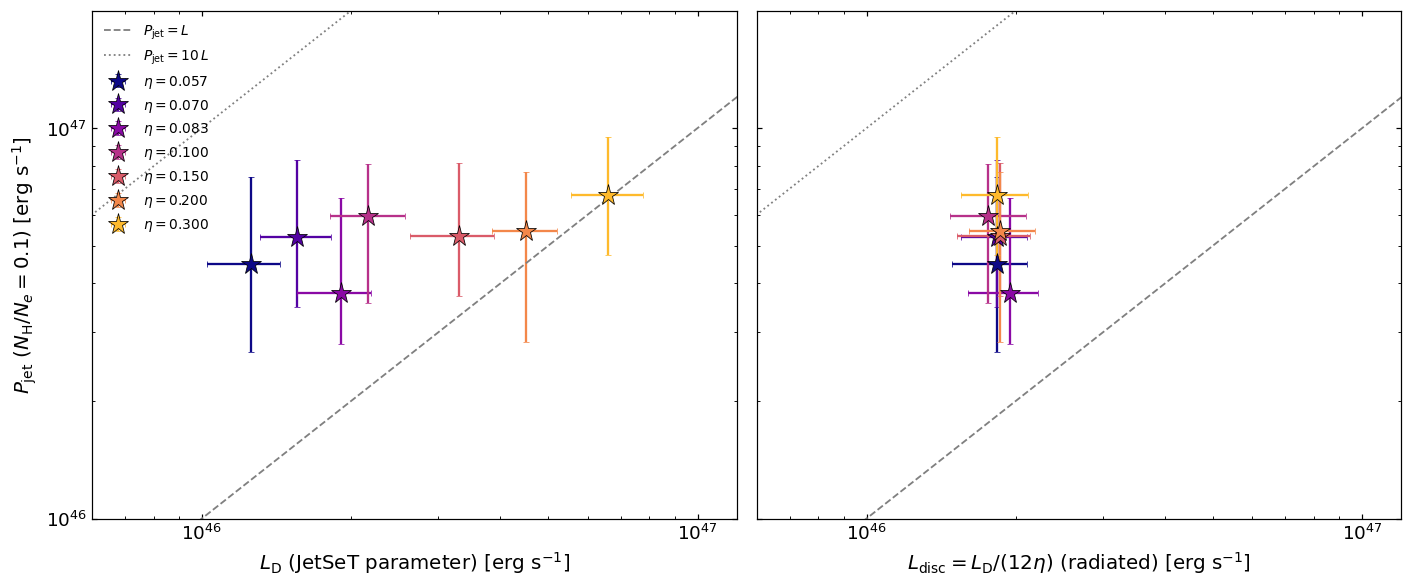

   eta | L_D [1e46] | L_disc [1e46] | P_jet [1e46] |  P/L_D | P/L_disc
 0.057 |       1.26 |          1.84 |         4.50 |    3.6 |      2.4
 0.070 |       1.56 |          1.83 |         5.26 |    3.4 |      2.9
 0.083 |       1.91 |          1.95 |         3.78 |    2.0 |      1.9
 0.100 |       2.17 |          1.76 |         5.95 |    2.7 |      3.4
 0.150 |       3.30 |          1.86 |         5.29 |    1.6 |      2.8
 0.200 |       4.51 |          1.86 |         5.45 |    1.2 |      2.9
 0.300 |       6.61 |          1.84 |         6.72 |    1.0 |      3.7


In [3]:
NH_PLOT = 0.1                      # same proton content as the published Table 5

with open('jet_energetics_summary.json') as f:
    en_summary = json.load(f)

colors = plt.cm.plasma(np.linspace(0.0, 0.85, len(eta_grid)))
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)

for eta, col in zip(eta_grid, colors):
    tag = eta_tag(eta)
    with open(f'summary_MCMC_{tag}_7p.json') as f:
        mc_eta = json.load(f)

    LD   = mc_eta['params']['L_Disk']                     # median, -err, +err
    Lrad = en_summary[f"{eta:.3f}"]['L_disc_rad']
    Pj   = en_summary[f"{eta:.3f}"]['P_jet'][f"NH={NH_PLOT:g}"]

    for ax, L in zip(axes, [LD, Lrad]):
        ax.errorbar(L[0], Pj[0], xerr=[[L[1]], [L[2]]], yerr=[[Pj[1]], [Pj[2]]],
                    fmt='*', ms=14, color=col, mec='k', mew=0.5, capsize=2,
                    label=rf'$\eta = {eta:.3f}$')

xx = np.logspace(45.7, 47.3, 10)
for ax in axes:
    ax.plot(xx, xx, '--', color='gray', lw=1.2, label=r'$P_{\rm jet} = L$')
    ax.plot(xx, 10 * xx, ':', color='gray', lw=1.2, label=r'$P_{\rm jet} = 10\,L$')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(6e45, 1.2e47)
    ax.set_ylim(1e46, 2e47)

axes[0].set_xlabel(r'$L_{\rm D}$ (JetSeT parameter) [erg s$^{-1}$]')
axes[1].set_xlabel(r'$L_{\rm disc} = L_{\rm D}/(12\eta)$ (radiated) [erg s$^{-1}$]')
axes[0].set_ylabel(rf'$P_{{\rm jet}}$ ($N_{{\rm H}}/N_e = {NH_PLOT:g}$) [erg s$^{{-1}}$]')
axes[0].legend(fontsize=9, frameon=False, loc='upper left')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'jet_power_vs_Ldisc_comparison.png'), bbox_inches='tight')
plt.show()

# numbers for the slide
print(f"{'eta':>6s} | {'L_D [1e46]':>10s} | {'L_disc [1e46]':>13s} | {'P_jet [1e46]':>12s} | "
      f"{'P/L_D':>6s} | {'P/L_disc':>8s}")
for eta in eta_grid:
    with open(f'summary_MCMC_{eta_tag(eta)}_7p.json') as f:
        LD = json.load(f)['params']['L_Disk'][0]
    Lr = en_summary[f"{eta:.3f}"]['L_disc_rad'][0]
    P  = en_summary[f"{eta:.3f}"]['P_jet'][f"NH={NH_PLOT:g}"][0]
    print(f"{eta:6.3f} | {LD/1e46:10.2f} | {Lr/1e46:13.2f} | {P/1e46:12.2f} | {P/LD:6.1f} | {P/Lr:8.1f}")

## Spin needed by the jets vs proton content

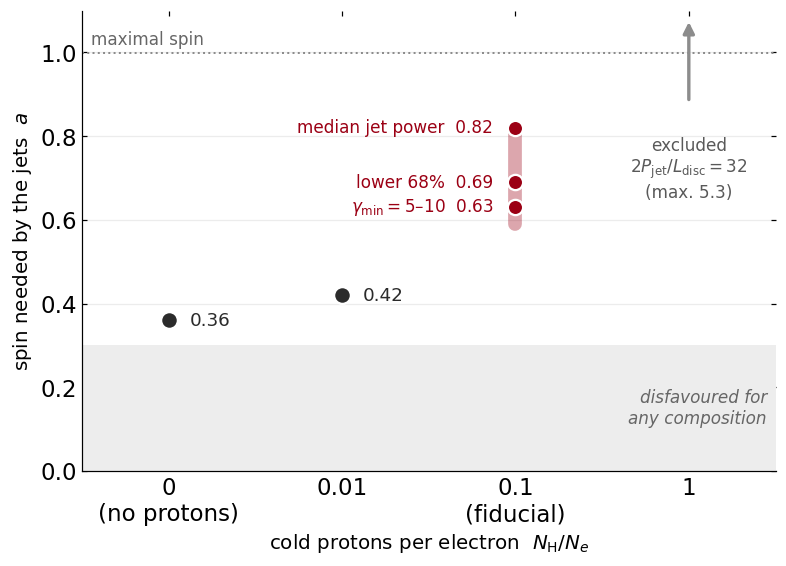

In [4]:
import numpy as np
import matplotlib.pyplot as plt

RED, INK, GREY = '#9b0014', '#2b2b2b', '0.55'
plt.rcParams.update({'font.size': 15})

# spin needed for each proton content
a_noprot = 0.36                                   # N_H/N_e = 0
a_001    = 0.42                                   # N_H/N_e = 0.01
a_fid    = {'median jet power': 0.82,             # N_H/N_e = 0.1, gamma_min = 2.1
            'lower 68%':        0.69,
            r'$\gamma_{\min} = 5$–$10$': 0.63}    # range 0.59-0.67
a_fid_range = [0.59, 0.82]
ratio_NH1, ratio_max = 32, 5.3                    # 2P_jet/L_disc for N_H/N_e = 1, and spin maximum

fig, ax = plt.subplots(figsize=(7.4, 5.4))
x = np.arange(4)

# low spin disfavoured, maximal spin
ax.axhspan(0, 0.3, color='0.93', lw=0)
ax.text(3.45, 0.15, 'disfavoured for\nany composition', ha='right', va='center',
        fontsize=11, color='0.4', style='italic')
ax.axhline(0.998, color=GREY, ls=':', lw=1.3)
ax.text(-0.45, 1.01, 'maximal spin', fontsize=11, color='0.4', va='bottom')

# no protons and N_H/N_e = 0.01
ax.plot([0, 1], [a_noprot, a_001], 'o', ms=11, color=INK, mec='white', mew=1.5, zorder=4)
ax.text(0.12, a_noprot, f'{a_noprot:.2f}', va='center', fontsize=12, color=INK)
ax.text(1.12, a_001,    f'{a_001:.2f}',    va='center', fontsize=12, color=INK)

# fiducial N_H/N_e = 0.1
ax.plot([2, 2], a_fid_range, color=RED, lw=9, alpha=0.35, solid_capstyle='round', zorder=2)
for lab, a in a_fid.items():
    ax.plot(2, a, 'o', ms=10, color=RED, mec='white', mew=1.5, zorder=4)
    ax.text(1.87, a, f'{lab}  {a:.2f}', ha='right', va='center', fontsize=11, color=RED)

# N_H/N_e = 1: excluded
ax.annotate('', xy=(3, 1.08), xytext=(3, 0.88),
            arrowprops=dict(arrowstyle='-|>', color=GREY, lw=2.2))
ax.text(3, 0.80, f'excluded\n$2P_{{\\rm jet}}/L_{{\\rm disc}} = {ratio_NH1}$\n(max. {ratio_max})',
        ha='center', va='top', fontsize=11, color='0.35')

ax.set_xticks(x)
ax.set_xticklabels(['0\n(no protons)', '0.01', '0.1\n(fiducial)', '1'])
ax.set_xlim(-0.5, 3.5)
ax.set_ylim(0, 1.1)
ax.set_xlabel(r'cold protons per electron  $N_{\rm H}/N_e$')
ax.set_ylabel(r'spin needed by the jets  $a$')
ax.grid(axis='y', color='#ececec', lw=0.8)
ax.set_axisbelow(True)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)

plt.tight_layout()
plt.savefig('spin_composition.png', dpi=250)
plt.show()